In [1]:
# ==========================================
# Block 1 - Import & Config
# ==========================================
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from scipy.optimize import minimize, differential_evolution
import matplotlib.pyplot as plt
from adjustText import adjust_text
import matplotlib.lines as mlines
from matplotlib.patches import Patch
from matplotlib.transforms import Bbox
import math
import random
import warnings
warnings.filterwarnings('ignore')

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

ALPHA = 1e-4

In [2]:
# ==========================================
# Block 2 - Load & Align Data
# ==========================================
# Read text accuracy
text_df = pd.read_csv("eval_results/text_accuracy.csv")
text_df.columns = text_df.columns.str.strip()

# Read multimodal accuracy
mm_df = pd.read_csv("eval_results/multimodal_accuracy.csv")
mm_df.columns = mm_df.columns.str.strip()

# Identify ckpt columns
ckpt_cols = [c for c in mm_df.columns if c.startswith("ckpt-")]

# Clean only ckpt columns
mm_df[ckpt_cols] = mm_df[ckpt_cols].apply(
    lambda col: col.astype(str)
                   .str.replace('%', '', regex=False)
                   .replace('Error', np.nan)
                   .astype(float)
) / 100

# Standardize model naming
mm_df["ModelName"] = mm_df["BaseModel"].str.split('/').str[-1]

# Align models
common_models = sorted(set(text_df["model_name"]) & set(mm_df["ModelName"]))
text_aligned = text_df[text_df["model_name"].isin(common_models)].set_index("model_name")
mm_aligned = mm_df[mm_df["ModelName"].isin(common_models)].set_index("ModelName")

print(f"Common models: {len(common_models)}")

Common models: 34


In [3]:
# ==========================================
# Block 3 - CKPT Info
# ==========================================
ALL_CKPTS = [f'ckpt-{i}' for i in range(3000, 24001, 3000)]
ALL_CKPTS = [c for c in ALL_CKPTS if c in mm_aligned.columns]
TOKENS_PER_CKPT = 8192 * 512
D_all_np = np.array([int(c.split('-')[1]) for c in ALL_CKPTS], dtype=float) \
           * TOKENS_PER_CKPT / 1e9

print(f"Available ckpts ({len(ALL_CKPTS)}): {ALL_CKPTS}")
print(f"D_all_np: {D_all_np}")

Available ckpts (8): ['ckpt-3000', 'ckpt-6000', 'ckpt-9000', 'ckpt-12000', 'ckpt-15000', 'ckpt-18000', 'ckpt-21000', 'ckpt-24000']
D_all_np: [ 12.582912  25.165824  37.748736  50.331648  62.91456   75.497472
  88.080384 100.663296]


In [4]:
# ==========================================
# Block 4 - Train / Holdout Split
# ==========================================
HOLDOUT_MODELS = ['Qwen2.5-72B-Instruct', 'Qwen2.5-72B']
train_models = [m for m in common_models if m not in HOLDOUT_MODELS]

# Training trajectory matrix
L_train_np = mm_aligned.loc[train_models, ALL_CKPTS].values.astype(float)

# Start point
L_start_np = L_train_np[:, 0]
D_start = D_all_np[0]

print(f"Train models: {len(train_models)}")
print(f"L_train_np shape: {L_train_np.shape}")
print(f"Start ckpt: {ALL_CKPTS[0]}, D_start={D_start:.4f}")
print(f"NaN count: {np.isnan(L_train_np).sum()}")

Train models: 32
L_train_np shape: (32, 8)
Start ckpt: ckpt-3000, D_start=12.5829
NaN count: 0


In [5]:
# ==========================================
# Block 5 - PCA Preparation
# ==========================================
benchmark_cols = list(text_aligned.columns)  # use all columns except model_name
X_train = text_aligned.loc[train_models, benchmark_cols].values

max_pc = min(len(train_models) - 1, len(benchmark_cols))
pca = PCA(n_components=max_pc)
X_pca = pca.fit_transform(X_train)

cumvar = np.cumsum(pca.explained_variance_ratio_)
n_pc = int(np.argmax(cumvar >= 0.95)) + 1
n_pc = max(1, min(n_pc, max_pc))
X_pca = X_pca[:, :n_pc]

S_list = [X_pca[:, i] for i in range(n_pc)]

print(f"PCA n_pc = {n_pc} (95% variance retained)")
print(f"X_pca shape: {X_pca.shape}")

PCA n_pc = 12 (95% variance retained)
X_pca shape: (32, 12)


In [6]:
# ==========================================
# Block 6 - Loss Function & Optimization
# ==========================================
def huber_loss(x, delta=1.0):
    abs_x = np.abs(x)
    return np.where(abs_x <= delta, 0.5 * x**2, delta * (abs_x - 0.5 * delta))

def fit_acc_full(params, S_list, D, L, alpha=ALPHA):
    A, B0, Bm, P0 = params[:4]
    k_coeffs = params[4:]
    S = sum(k * s_data for k, s_data in zip(k_coeffs, S_list))
    ln_D = np.log(D)
    L_pred = A * S[:, None] + (B0 - Bm * S[:, None]) * ln_D[None, :] + P0
    absorption = B0 - Bm * S
    penalty = 1e5 * np.sum(absorption[absorption < 0] ** 2)
    valid_mask = ~np.isnan(L)
    residual = L_pred[valid_mask] - L[valid_mask]
    return np.sum(huber_loss(residual)) + penalty + alpha * np.sum(k_coeffs ** 2)

def run_optimization_full(S_list, D, L, n_pc, seed=RANDOM_SEED):
    args = (S_list, D, L, ALPHA)
    bounds_de = [(0, 10.), (1e-6, 10.), (1e-6, 10.), (-10., 10.)] + [(-50., 50.)] * n_pc
    global_res = differential_evolution(
        fit_acc_full, bounds=bounds_de, args=args,
        strategy='best1bin', maxiter=2000, popsize=8,
        workers=-1, seed=seed, disp=False)
    bounds_loc = [(1e-6, None), (1e-6, None), (1e-6, None), (None, None)] + [(None, None)] * n_pc
    return minimize(fit_acc_full, x0=global_res.x, args=args,
                    method='L-BFGS-B', bounds=bounds_loc,
                    options={'maxiter': 1000000, 'maxfun': 1000000, 'disp': False})

def compute_mae_full(params, S_list, D, L):
    A, B0, Bm, P0 = params[:4]
    k_coeffs = params[4:]
    S = sum(k * s_data for k, s_data in zip(k_coeffs, S_list))
    L_pred = A * S[:, None] + (B0 - Bm * S[:, None]) * np.log(D)[None, :] + P0
    valid_mask = ~np.isnan(L)
    return np.mean(np.abs(L_pred[valid_mask] - L[valid_mask]))

print("Loss functions defined ✅")

Loss functions defined ✅


In [7]:
# ==========================================
# Block 7 - Run Fitting
# ==========================================
print("\n🚀 Full model fitting...")
res_full = run_optimization_full(S_list, D_all_np, L_train_np, n_pc)
params_full = res_full.x
A_f, B0_f, Bm_f, P0_f = params_full[:4]
k_full = params_full[4:]
mae_full = compute_mae_full(params_full, S_list, D_all_np, L_train_np)

print(f"Train MAE = {mae_full*100:.4f}%")


🚀 Full model fitting...
Train MAE = 1.2868%


In [8]:
# ==========================================
# Block 8 - Normalize k coefficients
# ==========================================
# Extract parameters from fitting
A_f, B0_f, Bm_f, P0_f = params_full[:4]
k_full = params_full[4:]

# Norm of k vector
k_norm = np.linalg.norm(k_full)

# Normalize k
k_normalized = k_full / k_norm

# Adjust A and Bm
A_true = A_f * k_norm
Bm_true = Bm_f * k_norm

print(f"\n=== Normalization Results ===")
print(f"Normalized k coefficients ({n_pc} PCs):")
for i, k_val in enumerate(k_normalized, start=1):
    end_char = '\n' if i % 3 == 0 else ',  '
    print(f"  k{i:<2} = {k_val:.6f}", end=end_char)
print()
print(f"A={A_true:.6f}, B0={B0_f:.6f}, Bm={Bm_true:.6f}, P0={P0_f:.6f}")


=== Normalization Results ===
Normalized k coefficients (12 PCs):
  k1  = -0.359406,    k2  = 0.248109,    k3  = 0.146306
  k4  = -0.017796,    k5  = 0.012541,    k6  = -0.036830
  k7  = 0.109818,    k8  = -0.134554,    k9  = 0.124352
  k10 = -0.252835,    k11 = 0.565329,    k12 = -0.597397

A=0.231220, B0=0.015425, Bm=0.008627, P0=0.434057


In [9]:
# ==========================================
# Block 9 - Predict Holdout Trajectories
# ==========================================
# Prepare PCA features for holdout models
benchmark_cols = list(text_aligned.columns)  # all columns except model_name
X_72b = text_aligned.loc[HOLDOUT_MODELS, benchmark_cols].values
X_pca_72b = pca.transform(X_72b)[:, :n_pc]

# Compute S values using normalized k
S_72b = sum(k * X_pca_72b[:, i] for i, k in enumerate(k_normalized))
ln_D = np.log(D_all_np)

# Predict trajectories using adjusted A_true and Bm_true
L_pred_full_72b = (A_true * S_72b[:, None]
                   + (B0_f - Bm_true * S_72b[:, None]) * ln_D[None, :]
                   + P0_f)

# Get true trajectories from multimodal dataset
L_true_72b = mm_aligned.loc[HOLDOUT_MODELS, ALL_CKPTS].values.astype(float)

# Output MAE for each holdout model
print("\n=== Holdout Prediction Results ===")
for i, model in enumerate(HOLDOUT_MODELS):
    valid = ~np.isnan(L_true_72b[i])
    mae_f = np.mean(np.abs(L_pred_full_72b[i][valid] - L_true_72b[i][valid]))
    print(f"{model}:")
    print(f"  MAE = {mae_f*100:.4f}%")

N_CKPT_PLOT = 4   # only plot first 4 ckpts
D_plot      = D_all_np[:N_CKPT_PLOT]

# --- Training set X and Y ---
S_train_full = sum(k * s_data for k, s_data in zip(k_normalized, S_list))
X_train_full = (A_true * S_train_full[:, None]
                + (B0_f - Bm_true * S_train_full[:, None]) * np.log(D_plot)[None, :])
Y_train_plot = L_train_np[:, :N_CKPT_PLOT]  # limit to first N_CKPT_PLOT ckpts

# --- Holdout set X and Y ---
benchmark_cols = list(text_aligned.columns)
X_holdout = text_aligned.loc[HOLDOUT_MODELS, benchmark_cols].values
X_pca_holdout = pca.transform(X_holdout)[:, :n_pc]
S_holdout_full = sum(k * X_pca_holdout[:, i] for i, k in enumerate(k_normalized))

X_72b_full = (A_true * S_holdout_full[:, None]
              + (B0_f - Bm_true * S_holdout_full[:, None]) * np.log(D_plot)[None, :])
Y_72b_true = mm_aligned.loc[HOLDOUT_MODELS, ALL_CKPTS[:N_CKPT_PLOT]].values.astype(float)


=== Holdout Prediction Results ===
Qwen2.5-72B-Instruct:
  MAE = 0.3579%
Qwen2.5-72B:
  MAE = 2.0883%


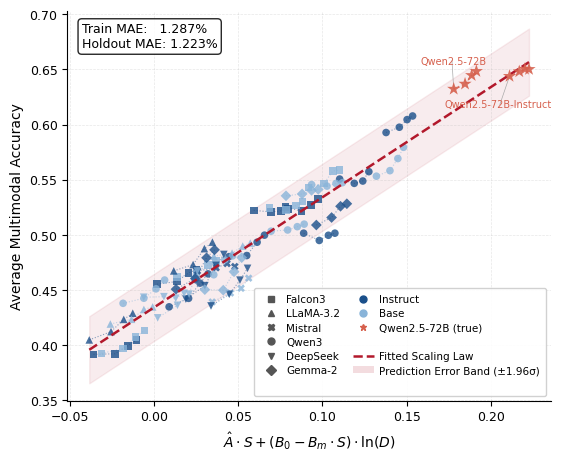

In [10]:
# ==========================================
# Block 10 - Plot Training & Holdout Trajectories
# ==========================================

# --- Model family & type mapping ---
def get_family(name):
    n = name.lower()
    if 'qwen3'    in n: return 'Qwen3'
    if 'falcon3'  in n: return 'Falcon3'
    if 'llama'    in n: return 'LLaMA-3.2'
    if 'gemma'    in n: return 'Gemma-2'
    if 'deepseek' in n: return 'DeepSeek'
    if 'mistral'  in n: return 'Mistral'
    return 'Other'

families_train = [get_family(m) for m in train_models]
model_types    = ['chat' if i % 2 == 0 else 'base'
                  for i in range(len(train_models))]
unique_families = list(dict.fromkeys(families_train))

MARKER_MAP = {
    'Qwen3'    : 'o',
    'Falcon3'  : 's',
    'LLaMA-3.2': '^',
    'Gemma-2'  : 'D',
    'DeepSeek' : 'v',
    'Mistral'  : 'X',
    'Qwen2.5'  : '*',
}
COLOR_MAP = {
    'chat'        : '#1a4f8a',
    'base'        : '#89b4d9',
    'holdout_true': '#D6604D',
}
FIG_HEIGHT  = 4.5
FIG_WIDTH   = 11.0
FONT_SIZE   = 9
LABEL_SIZE  = 10
MARKER_SIZE = 30
LEGEND_SIZE = 7.5
LINE_WIDTH  = 1.8

# Calculate residual std for 95% CI
Y_pred_train_full = X_train_full + P0_f
valid_tr = ~np.isnan(Y_train_plot)
std_full = np.std(Y_pred_train_full[valid_tr] - Y_train_plot[valid_tr])

# Plot settings
CI_Z = 1.96
fig, ax = plt.subplots(1, 1, figsize=(FIG_WIDTH / 2, FIG_HEIGHT),
                       constrained_layout=True)

X_tr = X_train_full
X_ho = X_72b_full
xlabel = r'$\hat{A} \cdot S + (B_0 - B_m \cdot S) \cdot \ln(D)$'
P0 = P0_f
mae_tr = mae_full
std_res = std_full

all_scatter_x = []
all_scatter_y = []

# --- Training set scatter + lines ---
for m_idx, m_name in enumerate(train_models):
    fam = families_train[m_idx]
    mtype = model_types[m_idx]
    marker = MARKER_MAP.get(fam, 'o')
    color = COLOR_MAP[mtype]

    x_row = X_tr[m_idx]
    y_row = Y_train_plot[m_idx]
    valid = ~np.isnan(y_row)

    if valid.sum() < 1:
        continue

    ax.plot(x_row[valid], y_row[valid],
            color=color, linewidth=0.8,
            linestyle=':', alpha=0.5, zorder=2)

    ax.scatter(x_row[valid], y_row[valid],
               marker=marker, color=color,
               s=MARKER_SIZE, alpha=0.8,
               edgecolors='none', zorder=3)

    all_scatter_x.extend(x_row[valid].tolist())
    all_scatter_y.extend(y_row[valid].tolist())

# --- Fitted line & 95% CI ---
x_min = min(np.array(all_scatter_x).min(), X_ho.min())
x_max = max(np.array(all_scatter_x).max(), X_ho.max())
x_line = np.linspace(x_min, x_max, 200)
y_line = x_line + P0

ax.plot(x_line, y_line,
        color='#B2182B', linewidth=LINE_WIDTH,
        linestyle='--', zorder=4)

ax.fill_between(x_line,
                y_line - CI_Z * std_res,
                y_line + CI_Z * std_res,
                color='#B2182B', alpha=0.08, zorder=1)

# --- Holdout true points + lines ---
texts_72b = []
ho_xs = []
ho_ys = []

for i, model in enumerate(HOLDOUT_MODELS):
    x_row = X_ho[i]
    y_row = Y_72b_true[i]
    valid = ~np.isnan(y_row)

    if valid.sum() < 1:
        continue

    ax.plot(x_row[valid], y_row[valid],
            color=COLOR_MAP['holdout_true'],
            linewidth=1.2, linestyle=':',
            alpha=0.8, zorder=4)

    ax.scatter(x_row[valid], y_row[valid],
               marker=MARKER_MAP['Qwen2.5'],
               color=COLOR_MAP['holdout_true'],
               s=100, alpha=0.9,
               edgecolors='none', zorder=5)

    ho_xs.extend(x_row[valid].tolist())
    ho_ys.extend(y_row[valid].tolist())

    first = np.where(valid)[0][0]

    if model == "Qwen2.5-72B":
        va_align = 'top'
        y_offset = 0.030
        x_offset = -0.020
        ha_align = 'left'
        text_x = x_row[first] + x_offset
        text_y = y_row[first] + y_offset
    elif model == "Qwen2.5-72B-Instruct":
        va_align = 'bottom'
        y_offset = 0.030
        x_offset = 0.025
        ha_align = 'right'
        text_x = x_row[first] + x_offset
        text_y = y_row[first] - y_offset
    else:
        va_align = 'bottom'
        y_offset = 0.0
        x_offset = 0.0
        ha_align = 'left'
        text_x = x_row[first]
        text_y = y_row[first]

    t = ax.text(
        text_x, text_y,
        model,
        fontsize=7, color=COLOR_MAP['holdout_true'],
        va=va_align, ha=ha_align, zorder=6,
    )
    texts_72b.append(t)

    fig.canvas.draw()
    bbox = t.get_window_extent(fig.canvas.renderer)
    bbox_data = Bbox(ax.transData.inverted().transform(bbox))

    arrow_end_x = (bbox_data.x0 + bbox_data.x1) / 2
    arrow_end_y = (bbox_data.y0 + bbox_data.y1) / 2

    ax.annotate(
        '',
        xy=(x_row[first], y_row[first]),        
        xytext=(arrow_end_x, arrow_end_y),      
        arrowprops=dict(
            arrowstyle='-',
            color='#aaaaaa',
            lw=0.5,
            shrinkA=0,
            shrinkB=0
        )
    )

# --- MAE annotation ---
mae_ho_list = []
for i in range(len(HOLDOUT_MODELS)):
    valid = ~np.isnan(Y_72b_true[i])
    if valid.sum() > 0:
        y_pred_ho = X_ho[i][valid] + P0
        mae_ho_list.append(np.mean(np.abs(y_pred_ho - Y_72b_true[i][valid])))
mae_ho = np.mean(mae_ho_list)

ax.text(0.03, 0.97,
        f"Train MAE:   {mae_tr*100:.3f}%\n"
        f"Holdout MAE: {mae_ho*100:.3f}%",
        transform=ax.transAxes, fontsize=FONT_SIZE,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

# --- Axis labels & style ---
ax.set_xlabel(xlabel, fontsize=LABEL_SIZE)
ax.set_ylabel('Average Multimodal Accuracy', fontsize=LABEL_SIZE)
ax.tick_params(labelsize=FONT_SIZE)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.3, linewidth=0.5)

# --- Legend ---
shape_handles = [
    mlines.Line2D([], [], color='#555555',
                  marker=MARKER_MAP[fam], linestyle='None',
                  markersize=5, label=fam)
    for fam in unique_families
]
color_handles = [
    mlines.Line2D([], [], color=COLOR_MAP['chat'],
                  marker='o', linestyle='None',
                  markersize=5, label='Instruct'),
    mlines.Line2D([], [], color=COLOR_MAP['base'],
                  marker='o', linestyle='None',
                  markersize=5, label='Base'),
    mlines.Line2D([], [], color=COLOR_MAP['holdout_true'],
                  marker=MARKER_MAP['Qwen2.5'], linestyle='None',
                  markersize=5, label='Qwen2.5-72B (true)'),
]
fit_handle = mlines.Line2D([], [], color='#B2182B',
                            linewidth=LINE_WIDTH, linestyle='--',
                            label='Fitted Scaling Law')
ci_handle = Patch(facecolor='#B2182B', alpha=0.15, edgecolor='none',
                  label='Prediction Error Band (±1.96σ)')
separator = Patch(color='none', label='')

ax.legend(
    handles=shape_handles + [separator] + color_handles
            + [separator, fit_handle, ci_handle],
    fontsize=LEGEND_SIZE, framealpha=0.9, edgecolor='#cccccc',
    loc='lower right',
    ncol=2,
    handletextpad=0.5, borderpad=0.6,
    labelspacing=0.4, columnspacing=1.2,
)

# --- Show ---
plt.show()